# Week 2 Comparison: From-Scratch vs. LLaVA Stage 1 vs. LLaVA Stage 2 (LoRA)

This is the single place to see all three notebooks' results side by side. Each of `minimal_vlm_from_scratch.ipynb`, `minimal_vlm_llava_style.ipynb`, and `minimal_vlm_llava_stage2_lora.ipynb` runs in its own kernel and writes its fixed-set BLEU-4 result into a shared `comparison_results.json` file (via `eval_utils.save_result`) -- this notebook just reads that file back.

**Run this only after all three notebooks have run their `eval_utils` cell at least once** (in any order -- `save_result` merges into the file rather than overwriting other stages).


## 1. Load and display the comparison table

In [2]:
from eval_utils import load_comparison, print_comparison_table

print_comparison_table()


Stage                              BLEU-4
------------------------------------------
From-scratch                       0.0098
Stage 1 (LLaVA, projector only)    0.2049
Stage 2 (LoRA)                     0.4282
qwen2.5vl:7b                       0.1855
qwen2.5vl:3b                       0.2404
llama3.2-vision:11b                0.0191
minicpm-v                          0.0693
llava-phi3                         0.0679


## 2. Bar chart (the "suggested figure for the report" every notebook's Notes section mentions)

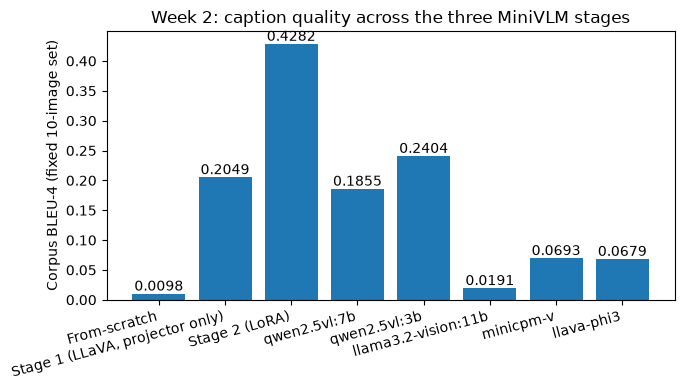

In [3]:
import matplotlib.pyplot as plt

results = load_comparison()
if not results:
    print("No results yet -- run each notebook's eval_utils cell first.")
else:
    stages = list(results.keys())
    scores = [results[s]["bleu4"] for s in stages]

    plt.figure(figsize=(7, 4))
    bars = plt.bar(stages, scores)
    plt.ylabel("Corpus BLEU-4 (fixed 10-image set)")
    plt.title("Week 2: caption quality across the three MiniVLM stages")
    plt.xticks(rotation=15, ha="right")
    for bar, score in zip(bars, scores):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{score:.4f}",
                  ha="center", va="bottom")
    plt.tight_layout()
    plt.show()


## 3. Side-by-side generated captions

Same fixed 10 images across all three stages -- picking a couple to actually read side by side (rather than just the aggregate BLEU-4) is what makes the qualitative progression visible, per every notebook's closing notes.

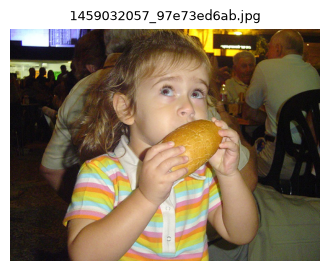

  ground truth                     A girl in a striped shirt holds a bun to her mouth .
  From-scratch                     a a man man and and a a woman woman are are sitting sitting on on a a bench bench . .
  Stage 1 (LLaVA, projector only)  A little girl is eating a cake .
  Stage 2 (LoRA)                   A little girl is eating a cake .
  qwen2.5vl:7b                     A young child enjoys a large sandwich in a restaurant setting.
  qwen2.5vl:3b                     A young girl eats a sandwich in a restaurant.
  llama3.2-vision:11b              The image shows a young girl eating a bread roll in a restaurant.

The girl is wearing a striped shirt and has blonde hair. She is holding a bread roll in both hands and appears to be taking a bite. In the background, there are several people sitting at tables, and a man is standing behind the girl. The atmosphere seems to be a casual dining experience, possibly at a restaurant or café.
  minicpm-v                        A young girl wit

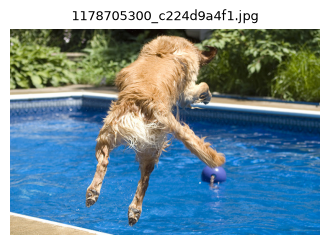

  ground truth                     a brown dog jumping into a pool after a bloe ball .
  From-scratch                     a a boy boy is is jumping jumping into into a a pool pool . .
  Stage 1 (LLaVA, projector only)  A dog jumps out of a pool .
  Stage 2 (LoRA)                   A dog jumps into a pool .
  qwen2.5vl:7b                     A golden retriever leaps into a swimming pool.
  qwen2.5vl:3b                     A dog leaps into a pool, its fur flying behind it.
  llama3.2-vision:11b              The image depicts a dog in mid-air, leaping over a pool. The dog's golden fur and wet appearance suggest it has just entered the water. Its front paws are extended, while its back paws are tucked in, and its head is turned to the right. The dog's ears are perked up, and its tail is held high.

The pool's blue water is visible below the dog, and a blue ball can be seen floating in the water. The pool's edge is visible on the right side of the image, with a concrete surface and a white 

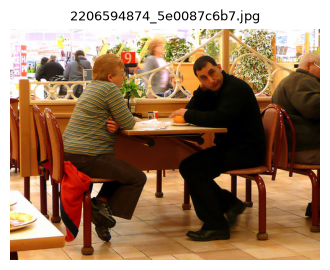

  ground truth                     A couple sits at a cramped table in a busy restaurant .
  From-scratch                     a a man man and and a a woman woman are are sitting sitting on on a a bench bench . .
  Stage 1 (LLaVA, projector only)  A man and a boy are sitting on a bench .
  Stage 2 (LoRA)                   A man and a woman sit at a table .
  qwen2.5vl:7b                     A man and a child sit at a table in a restaurant, with the man looking at the camera.
  qwen2.5vl:3b                     A man and a child sit at a table in a restaurant.
  llama3.2-vision:11b              This image captures a moment in a restaurant, where a man and a boy are seated at a table.

The man, with dark hair and dressed in a black sweater and black pants, sits on the right side of the table, while the boy, with short red hair, wears a green and white striped shirt and dark pants, sits on the left. A red bag is visible behind the boy's chair. The table is set with plates and utensils, and 

In [4]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from eval_utils import build_reference_lookup

IMAGE_DIR = Path("../data/flickr8k/Images")
CAPTIONS_FILE = "../data/flickr8k/captions.txt"
reference_lookup = build_reference_lookup(CAPTIONS_FILE)

results = load_comparison()
if results:
    n_examples = min(3, len(next(iter(results.values()))["image_names"]))
    for i in range(n_examples):
        image_name = next(iter(results.values()))["image_names"][i]
        image = Image.open(IMAGE_DIR / image_name)

        plt.figure(figsize=(4, 4))
        plt.imshow(image)
        plt.axis("off")
        plt.title(image_name, fontsize=9)
        plt.show()

        print(f"  {'ground truth':<32} {reference_lookup[image_name][0]}")
        for stage_name, r in results.items():
            print(f"  {stage_name:<32} {r['generated_captions'][i]}")
        print()


## 4. Notes for the reading log / report

- **This table is the quantitative headline for the Week 2 deliverable** — one metric (corpus BLEU-4), computed the same way, on the identical 10 images, across three architecturally distinct approaches (fully from-scratch, frozen-backbones-trained-projector, and LoRA-adapted LLM).
- **A higher number here is expected to trend Stage 2 > Stage 1 > from-scratch** if pretraining transfer is doing what it should — but as each notebook's Notes section says, if Stage 2 doesn't clearly beat Stage 1, that's a legitimate, reportable finding (evidence that the projector alone already captured most of the available alignment at this data/epoch scale), not a failure of the exercise.
- **`comparison_results.json`** (this notebook's data source) also holds every generated caption for all 10 fixed images per stage, not just the aggregate score -- useful for picking the 2-3 side-by-side qualitative examples Section 3 above surfaces, for the actual report.
